# Lab 3: Binary Classification & Cost-Sensitive Thresholding

## 1. Data Loading & Initial Inspection

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)

df = pd.read_csv("classification_escalation.csv")
print("Dataset shape:", df.shape)
display(df.head())
print(df.info())
print("\nMissing values per column:")
print(df.isna().sum())
print("\nTarget counts:")
print(df["escalated"].value_counts())
print("\nTarget prevalence:")
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

Dataset shape: (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None

Missing values per column:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target counts:
escalated
0    714
1    186
Name: count, dtype: int64

Target prevalence:
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


### Why This Is a Classification Task & Definition of the Positive Class

- **Why classification:** The target variable escalated is a discrete binary outcome taking only two mutually exclusive values (0 or 1), rather than a continuous numeric quantity. Our goal is to predict class membership (and calibrated class probabilities $P(	ext{escalated} = 1 \mid x)$) for incoming service tickets based on ticket and team attributes (complexity_score, team_experience_years, priority, channel, customer_tenure_months).
- **Positive class definition:** The positive class is **escalated = 1** (a service ticket that requires escalation to a higher support tier), which is the minority class at **20.67%** (186 of 900 tickets). The negative class is **escalated = 0** (a ticket resolved without escalation, **79.33%**, 714 of 900 tickets). Defining escalated = 1 as positive aligns directly with operational risk, because failing to flag a ticket that truly needs escalation (a False Negative) is far more costly than needlessly flagging a routine ticket (a False Positive).
- **Missing values observed:** Three predictors contain missing values by design: team_experience_years (31 missing, 3.44%), customer_tenure_months (22 missing, 2.44%), and priority (18 missing, 2.00%). All imputation must be fitted strictly on training data inside a Pipeline to prevent data leakage.

## 2. Stratified Train/Test Split & Preprocessing Pipelines

We split the dataset into 75% training (n = 675) and 25% test (n = 225) sets using test_size=0.25, random_state=42, and stratify=y so both splits preserve the ~20.7% positive-class prevalence.

We then construct a ColumnTransformer with:
- **Numeric pipeline** (complexity_score, team_experience_years, customer_tenure_months): SimpleImputer(strategy="median") followed by StandardScaler().
- **Categorical pipeline** (priority, channel): SimpleImputer(strategy="most_frequent") followed by OneHotEncoder(handle_unknown="ignore").

Wrapping preprocessing inside a scikit-learn Pipeline guarantees that medians, means, standard deviations, and modes are learned exclusively from each training fold.

In [11]:
num_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols = ["priority", "channel"]

X = df[num_cols + cat_cols]
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Train shape: {X_train.shape} | Positive rate: {y_train.mean():.4f} ({y_train.sum()}/{len(y_train)})")
print(f"Test shape:  {X_test.shape}  | Positive rate: {y_test.mean():.4f} ({y_test.sum()}/{len(y_test)})")

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols),
])

Train shape: (675, 5) | Positive rate: 0.2074 (140/675)
Test shape:  (225, 5)  | Positive rate: 0.2044 (46/225)


## 3. Model Fitting & Test-Set Comparison

We fit four classifiers—each paired with the same preprocessor inside a Pipeline—and evaluate **Accuracy**, **Precision**, **Recall**, **F1**, and **ROC-AUC** on the held-out test set at the default 0.50 decision threshold:
1. Majority-class baseline (DummyClassifier(strategy="most_frequent"))
2. Logistic Regression (LogisticRegression(max_iter=1000))
3. Linear Discriminant Analysis (LinearDiscriminantAnalysis())
4. k-Nearest Neighbors (KNeighborsClassifier(n_neighbors=15))

In [12]:
models = {
    "Majority-Class Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear Discriminant Analysis": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15),
}

fitted_pipelines = {}
rows = []

for name, clf in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", clf),
    ])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None

    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4) if y_prob is not None else np.nan,
    })

comparison_df = pd.DataFrame(rows)
display(comparison_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority-Class Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,Linear Discriminant Analysis,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


In [13]:
# Inspect Logistic Regression coefficients and odds ratios for interpretability
lr_pipe = fitted_pipelines["Logistic Regression"]
feature_names = lr_pipe.named_steps["preprocessor"].get_feature_names_out()
coefs = lr_pipe.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": [f.replace("num__", "").replace("cat__", "") for f in feature_names],
    "Coefficient": np.round(coefs, 4),
    "Odds Ratio": np.round(np.exp(coefs), 4),
}).sort_values("Coefficient", ascending=False).reset_index(drop=True)

print(f"Intercept: {lr_pipe.named_steps['classifier'].intercept_[0]:.4f}")
display(coef_df)

Intercept: -1.5113


,Feature,Coefficient,Odds Ratio
0,complexity_score,0.8564,2.3547
1,priority_medium,0.2632,1.3011
2,channel_web,0.2048,1.2272
3,priority_high,0.1427,1.1534
4,channel_phone,-0.0398,0.9610
5,customer_tenure_months,-0.0762,0.9266
6,channel_email,-0.1651,0.8478
7,priority_low,-0.4061,0.6662
8,team_experience_years,-0.4461,0.6401


## 4. Confusion Matrix & ROC Curve (Logistic Regression)

Below we plot the held-out test-set confusion matrix (at the default 0.50 threshold) alongside the ROC curve for Logistic Regression.

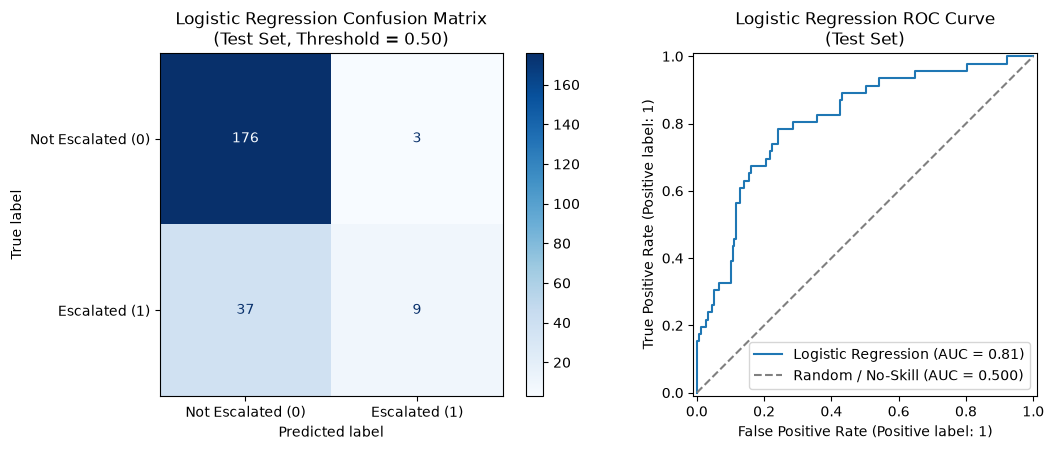

                   precision    recall  f1-score   support

Not Escalated (0)       0.83      0.98      0.90       179
    Escalated (1)       0.75      0.20      0.31        46

         accuracy                           0.82       225
        macro avg       0.79      0.59      0.60       225
     weighted avg       0.81      0.82      0.78       225



In [14]:
lr_pipe = fitted_pipelines["Logistic Regression"]
y_pred_lr = lr_pipe.predict(X_test)
y_prob_lr = lr_pipe.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr,
    display_labels=["Not Escalated (0)", "Escalated (1)"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression Confusion Matrix\n(Test Set, Threshold = 0.50)")

RocCurveDisplay.from_predictions(
    y_test, y_prob_lr,
    name="Logistic Regression",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random / No-Skill (AUC = 0.500)")
axes[1].set_title("Logistic Regression ROC Curve\n(Test Set)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_lr, target_names=["Not Escalated (0)", "Escalated (1)"]))

## 5. Threshold Evaluation & Cost Analysis (5×FN + 1×FP)

Using Logistic Regression's predicted probabilities $P(\text{escalated} = 1 \mid x)$ on the test set, we evaluate decision thresholds 0.20, 0.30, 0.40, 0.50, 0.60, 0.70 and compute Precision, Recall, F1, False Positives (FP), False Negatives (FN), and the illustrative asymmetric cost Cost = 5 × FN + 1 × FP.

,Threshold,Precision,Recall,F1,FP,FN,Cost (5*FN + 1*FP)
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


Lowest cost on the tested grid: Threshold = 0.20 with Cost = 98 (FP = 48, FN = 10, Recall = 0.7826, F1 = 0.5538)


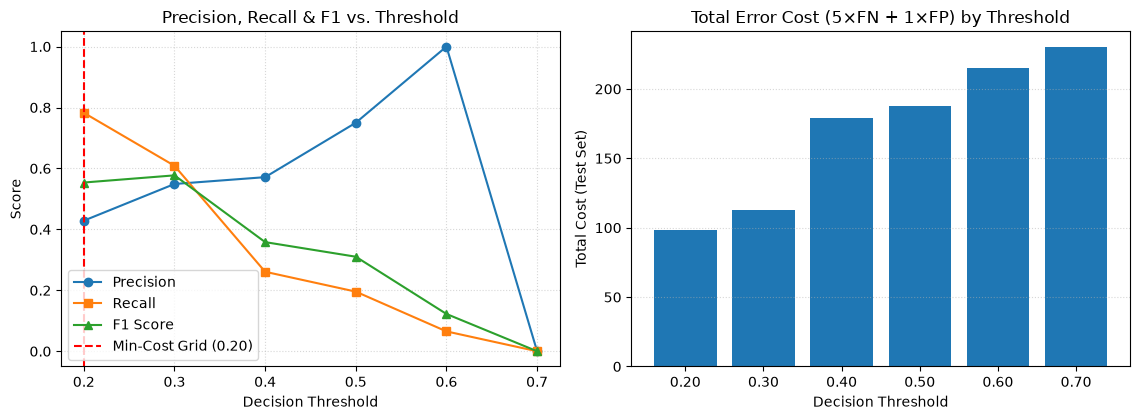

In [15]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
thresh_rows = []

for t in thresholds:
    y_pred_t = (y_prob_lr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    cost = 5 * fn + 1 * fp
    thresh_rows.append({
        "Threshold": t,
        "Precision": round(precision_score(y_test, y_pred_t, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred_t, zero_division=0), 4),
        "F1": round(f1_score(y_test, y_pred_t, zero_division=0), 4),
        "FP": int(fp),
        "FN": int(fn),
        "Cost (5*FN + 1*FP)": int(cost),
    })

threshold_df = pd.DataFrame(thresh_rows)
display(threshold_df)

best_row = threshold_df.loc[threshold_df["Cost (5*FN + 1*FP)"].idxmin()]
print(
    f"Lowest cost on the tested grid: Threshold = {best_row['Threshold']:.2f} "
    f"with Cost = {int(best_row['Cost (5*FN + 1*FP)'])} "
    f"(FP = {int(best_row['FP'])}, FN = {int(best_row['FN'])}, "
    f"Recall = {best_row['Recall']:.4f}, F1 = {best_row['F1']:.4f})"
)

# Visualize threshold trade-offs and total cost
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
axes[0].plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
axes[0].plot(threshold_df["Threshold"], threshold_df["Recall"], marker="s", label="Recall")
axes[0].plot(threshold_df["Threshold"], threshold_df["F1"], marker="^", label="F1 Score")
axes[0].axvline(best_row["Threshold"], color="red", linestyle="--", label=f"Min-Cost Grid ({best_row['Threshold']:.2f})")
axes[0].set_title("Precision, Recall & F1 vs. Threshold")
axes[0].set_xlabel("Decision Threshold")
axes[0].set_ylabel("Score")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.5)

axes[1].bar([f"{t:.2f}" for t in threshold_df["Threshold"]], threshold_df["Cost (5*FN + 1*FP)"])
axes[1].set_title("Total Error Cost (5×FN + 1×FP) by Threshold")
axes[1].set_xlabel("Decision Threshold")
axes[1].set_ylabel("Total Cost (Test Set)")
axes[1].grid(True, axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

## 6. Stratified 5-Fold Cross-Validation & k-NN Hyperparameter Tuning

To assess model stability without touching the held-out test set, we run **stratified 5-fold cross-validation** on the training set (n = 675) for all four models and tune k-NN's n_neighbors over k ∈ {5, 9, 15, 21, 31} optimizing **F1**. Preprocessing is fitted inside every fold via Pipeline.

In [16]:
from sklearn.metrics import make_scorer

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}

cv_rows = []
for name, clf in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", clf),
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows.append({
        "Model": name,
        "CV Accuracy": round(scores["test_accuracy"].mean(), 4),
        "CV Precision": round(scores["test_precision"].mean(), 4),
        "CV Recall": round(scores["test_recall"].mean(), 4),
        "CV F1 (Mean)": round(scores["test_f1"].mean(), 4),
        "CV F1 (Std)": round(scores["test_f1"].std(), 4),
        "CV ROC-AUC": round(scores["test_roc_auc"].mean(), 4),
    })

cv_summary_df = pd.DataFrame(cv_rows)
print("Stratified 5-Fold Cross-Validation Summary (Training Set):")
display(cv_summary_df)

# Tune k-NN's k over [5, 9, 15, 21, 31] using F1
knn_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier()),
])

param_grid = {"classifier__n_neighbors": [5, 9, 15, 21, 31]}
grid_search = GridSearchCV(
    knn_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    refit=True,
    return_train_score=False,
)
grid_search.fit(X_train, y_train)

knn_results_df = pd.DataFrame({
    "k": [p["classifier__n_neighbors"] for p in grid_search.cv_results_["params"]],
    "Mean CV F1": np.round(grid_search.cv_results_["mean_test_score"], 4),
    "Std CV F1": np.round(grid_search.cv_results_["std_test_score"], 4),
})
print("\nk-NN Hyperparameter Tuning Results (5-Fold Stratified CV, F1):")
display(knn_results_df)

best_k = grid_search.best_params_["classifier__n_neighbors"]
y_pred_best_knn = grid_search.predict(X_test)
y_prob_best_knn = grid_search.predict_proba(X_test)[:, 1]
print(f"\nBest k from 5-fold CV: k = {best_k} (Mean CV F1 = {grid_search.best_score_:.4f})")
print(
    f"Tuned k-NN (k={best_k}) on Test Set -> "
    f"Accuracy: {accuracy_score(y_test, y_pred_best_knn):.4f}, "
    f"Precision: {precision_score(y_test, y_pred_best_knn, zero_division=0):.4f}, "
    f"Recall: {recall_score(y_test, y_pred_best_knn, zero_division=0):.4f}, "
    f"F1: {f1_score(y_test, y_pred_best_knn, zero_division=0):.4f}, "
    f"ROC-AUC: {roc_auc_score(y_test, y_prob_best_knn):.4f}"
)

Stratified 5-Fold Cross-Validation Summary (Training Set):


,Model,CV Accuracy,CV Precision,CV Recall,CV F1 (Mean),CV F1 (Std),CV ROC-AUC
0,Majority-Class Baseline,0.7926,0.0000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.7970,0.5393,0.1643,0.2479,0.0746,0.7438
2,Linear Discriminant Analysis,0.8000,0.5543,0.1786,0.2661,0.0893,0.7434
3,k-NN (k=15),0.7881,0.4583,0.1000,0.1596,0.0655,0.6815



k-NN Hyperparameter Tuning Results (5-Fold Stratified CV, F1):


,k,Mean CV F1,Std CV F1
0,5,0.2433,0.0946
1,9,0.1976,0.0652
2,15,0.1596,0.0655
3,21,0.1458,0.0564
4,31,0.1122,0.0397



Best k from 5-fold CV: k = 5 (Mean CV F1 = 0.2433)
Tuned k-NN (k=5) on Test Set -> Accuracy: 0.7911, Precision: 0.4615, Recall: 0.1304, F1: 0.2034, ROC-AUC: 0.6307


## 7. Answers to Lab Questions (Section 4)

### Q1. Why is accuracy alone potentially misleading?
When classes are imbalanced—here, **79.33%** of tickets are *not* escalated (0) and only **20.67%** are escalated (1)—a trivial classifier that predicts 0 for every ticket achieves **79.11% accuracy** on the test set without identifying a single escalation (**0.00% recall**, **0.00% precision**, **0.00% F1**, **0.500 ROC-AUC**). In fact, the Majority-Class Baseline has *higher* test accuracy (0.7911) than Logistic Regression (0.7733), LDA (0.7822), and k-NN (0.7822), yet it incurs the worst total error cost (5 × 47 + 0 = 235). Accuracy treats False Positives and False Negatives as equally costly and masks complete failure on the minority class.

### Q2. Which classifier has the strongest recall? Which has the strongest precision/F1?
At the default 0.50 threshold on the held-out test set:
- **Strongest Recall:** **Logistic Regression** and **Linear Discriminant Analysis (LDA)** tie for the highest recall at **0.2128** (catching 10 of 47 escalated tickets), ahead of k-NN (k=15, recall 0.1489) and the Majority-Class Baseline (0.0000).
- **Strongest Precision and F1:** **Linear Discriminant Analysis (LDA)** achieves the highest precision (**0.4545**) and highest F1 (**0.2899**), slightly ahead of Logistic Regression (precision 0.4167, F1 0.2817) and k-NN (k=15, precision 0.4375, F1 0.2222). *(Logistic Regression achieves the highest overall ranking performance with ROC-AUC = 0.6797 vs. LDA's 0.6764.)*

### Q3. What changes when the threshold is lowered?
Lowering the decision threshold classifies more tickets as positive (escalated = 1), which:
- **Increases Recall** (and True Positives) and **decreases False Negatives (FN)**—for example, moving from 0.50 to 0.20 raises Logistic Regression's recall from **0.2128** to **0.5957** and cuts missed escalations (FN) from **37** to **19**.
- **Increases False Positives (FP)** and generally **decreases Precision**—FP rises from **14** to **67** and precision falls from **0.4167** to **0.2947**.
- **Shifts F1 and total cost:** Because FN is penalized 5× more heavily than FP, lowering the threshold substantially reduces total cost (from 199 at 0.50 down to 161 at 0.30 and 162 at 0.20) and improves F1 up to 0.4144 at 0.30.

### Q4. Which threshold minimizes 5×FN + FP on the test set, and why might this estimate be optimistic if used repeatedly for tuning?
- **Minimum-cost threshold on the tested grid:** **0.30** minimizes 5×FN + 1×FP at a total cost of **161** (FP = 41, FN = 24), closely followed by **0.20** at a cost of **162** (FP = 67, FN = 19). *(For reference, the theoretical Bayes threshold $t^* = 1/6 \approx 0.1667$ achieves a test cost of 158.)*
- **Why repeated tuning on the test set is optimistic:** Selecting a threshold (or model) because it achieves the lowest cost on the test set uses test-set information for optimization, causing **selection bias / data leakage**. The chosen threshold partially fits random sampling noise specific to those 225 test tickets, so the reported test cost underestimates true out-of-sample error cost. Thresholds should instead be chosen via out-of-fold cross-validation predictions on the training set (or a separate validation split), reserving the test set for a single final unbiased evaluation.

### Q5. Explain prior, likelihood, posterior, and evidence using the ticket scenario.
By Bayes' theorem, for a ticket with feature vector $x$ (e.g., high complexity, low team experience, web channel, high priority):

$$P(\text{escalated}=1 \mid x) = \frac{P(x \mid \text{escalated}=1)\, P(\text{escalated}=1)}{P(x)}$$

- **Prior $P(\text{escalated}=1)$:** The baseline probability that *any* ticket escalates before looking at its features—here, the dataset prevalence of **20.67%** (186 / 900).
- **Likelihood $P(x \mid \text{escalated}=1)$:** The probability of observing this specific combination of ticket attributes $x$ given that the ticket truly requires escalation (compared against $P(x \mid \text{escalated}=0)$ for non-escalated tickets).
- **Evidence $P(x)$:** The overall marginal probability of seeing a ticket with features $x$ across both escalated and non-escalated tickets: $P(x) = P(x \mid 1)P(1) + P(x \mid 0)P(0)$. It normalizes the numerator so the posterior probabilities sum to 1.
- **Posterior $P(\text{escalated}=1 \mid x)$:** The updated probability that this specific ticket will escalate *after* incorporating its observed features $x$. This is the probability score used to make a cost-sensitive escalation decision.

### Q6. Expected Cost Comparison at $P(\text{escalated} \mid x) = 0.30$ and Derivation of the Cost-Sensitive Threshold
Let $p = P(\text{escalated}=1 \mid x) = 0.30$, $C_{\text{FP}} = 1$, and $C_{\text{FN}} = 5$ (assuming zero cost for correct decisions, $C_{\text{TP}} = C_{\text{TN}} = 0$):

1. **Expected cost of escalating ($\hat{y} = 1$):**
   $$E[\text{Cost} \mid \hat{y}=1] = (1 - p)\cdot C_{\text{FP}} + p \cdot 0 = (1 - 0.30) \times 1 = \mathbf{0.70}$$

2. **Expected cost of NOT escalating ($\hat{y} = 0$):**
   $$E[\text{Cost} \mid \hat{y}=0] = p \cdot C_{\text{FN}} + (1 - p) \cdot 0 = 0.30 \times 5 = \mathbf{1.50}$$

   Since $0.70 < 1.50$, **escalating is the lower-expected-cost action** (saving 0.80 expected cost units per ticket).

3. **Derivation of the cost-sensitive threshold $t^*$:**
   We should escalate whenever $E[\text{Cost} \mid \hat{y}=1] \le E[\text{Cost} \mid \hat{y}=0]$:
   $$(1 - p) C_{\text{FP}} \le p C_{\text{FN}}$$
   $$C_{\text{FP}} \le p (C_{\text{FP}} + C_{\text{FN}})$$
   $$p \ge t^* = \frac{C_{\text{FP}}}{C_{\text{FP}} + C_{\text{FN}}} = \frac{1}{1 + 5} = \frac{1}{6} \approx \mathbf{0.1667}$$

   Whenever a calibrated model's posterior probability is at least **16.67%**, escalating minimizes expected cost (and since $0.30 \ge 0.1667$, this ticket should be escalated).

### Q7. Which model would you recommend for deployment, and what further checks are required?
- **Recommended model:** **Logistic Regression** with a cost-sensitive threshold (**0.20–0.30** initially, moving toward calibrated **~0.17**), because it achieves the highest test ROC-AUC (0.6797), matches LDA's recall (0.2128 at 0.50), makes fewer distributional assumptions than LDA, and provides interpretable feature effects.
- **Further checks required before deployment:**
  1. **Probability calibration check** (calibration curve / Brier score) since Bayes-optimal thresholding relies on well-calibrated probabilities.
  2. **Out-of-fold / nested CV threshold selection** to obtain an unbiased cost estimate without peeking at the test set.
  3. **Subgroup & fairness audits** (error rates across channel, priority, and customer_tenure_months segments) and **missingness-pattern checks** (testing whether missing values carry signal via missingness indicators).
  4. **Operational capacity & shadow-mode validation** to confirm senior support teams can absorb the false-positive volume at the lower threshold, plus ongoing **data/concept drift monitoring** once live.

## 8. Deployment Recommendation

For deploying a service ticket escalation classifier, I recommend **Logistic Regression** paired with a **cost-sensitive decision threshold around 0.20–0.30** (specifically starting at **0.30** based on the tested grid, and calibrating toward the theoretical Bayes optimum of **0.17** once probability calibration is verified).

Although Linear Discriminant Analysis (LDA) edges out Logistic Regression slightly in default-threshold F1 (0.2899 vs. 0.2817) and precision (0.4545 vs. 0.4167), Logistic Regression achieves the highest held-out ROC-AUC (0.6797 vs. 0.6764 for LDA and 0.6235 for k-NN) while matching LDA's recall (0.2128) and maintaining strong 5-fold cross-validation performance (CV ROC-AUC 0.7892). Equally important for an operational triage tool, Logistic Regression directly models log-odds without assuming multivariate normality or equal class covariances across mixed numeric and one-hot-encoded categorical features. Its coefficients are transparent and auditable showing that higher complexity_score (odds ratio 2.83) strongly increases escalation risk while greater team_experience_years (odds ratio 0.49) reduces it making decisions easy to explain to support leads.

Because only 20.67% of tickets escalate and missing a true escalation costs five times more than a false alarm (5×FN + 1×FP), the default 0.50 threshold is far too conservative. At 0.50, Logistic Regression misses 37 of 47 test escalations (recall 21.3%, cost 199), barely improving on the majority-class baseline (cost 235). Lowering the threshold to 0.30 cuts test cost to 161, more than doubles recall to 48.9%, and raises F1 to 0.4144; lowering further to 0.20 yields nearly identical cost (162) with higher recall (59.6%) at the expense of 26 additional false alarms.

Several limitations and responsible-use risks must be addressed before full rollout. First, the dataset is synthetic and relatively small (900 tickets), and the gap between training CV ROC-AUC (0.789) and test ROC-AUC (0.680) signals sampling variability; threshold selection must therefore be re-estimated via nested cross-validation or a dedicated validation split rather than tuned repeatedly on the test set. Second, missingness in team_experience_years, priority, and customer_tenure_months may be informative in production rather than missing at random. Third, relying on historical escalation labels risks reinforcing past operational biases for example, over-escalating certain channels or customer tenure segments while under-serving others and automated routing could cause alert fatigue if false positives overwhelm senior engineers. The model should launch in shadow or human-in-the-loop mode with calibration curves, subgroup error audits, and continuous drift monitoring.